# Iterative Solvers

**Seong Cho** · ACME Volume 1, Lab 15

**Lab objective:** approximate the solutions of large linear systems $A\mathbf{x} = \mathbf{b}$ iteratively, since Gaussian elimination or matrix factorizations could require trillions of floating point operations (FLOPs), by implementing three popular iterative methods: Jacobi, Gauss-Seidel, and Successive Over-Relaxation.

<sub>Lab specification from the *Volume 1* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse import linalg as spla

Let $\mathbf{x}^{(k)}$ denote the $k$th iteration of an iterative method for solving $A\mathbf{x} = \mathbf{b}$, and $x_i^{(k)}$ its $i$th component. Like other iterative methods, there are two stopping parameters, a very small $\epsilon > 0$ and an integer $N \in \mathbb{N}$, and iterations continue until either

$$\|\mathbf{x}^{(k-1)} - \mathbf{x}^{(k)}\| < \epsilon \quad \text{or} \quad k > N. \tag{16.1}$$

## The Jacobi Method

The Jacobi method is a simple but powerful method for solving certain kinds of large linear systems: solve for each variable in terms of the others, then use the previous values to update each approximation. For the (very small) system

$$\begin{aligned} 2x_1 \phantom{{}+3x_2} - x_3 &= 3 \\ -x_1 + 3x_2 + 2x_3 &= 3 \\ x_2 + 3x_3 &= -1 \end{aligned}$$

solving the first equation for $x_1$, the second for $x_2$, and the third for $x_3$ gives

$$x_1 = \tfrac{1}{2}(3 + x_3), \qquad x_2 = \tfrac{1}{3}(3 + x_1 - 2x_3), \qquad x_3 = \tfrac{1}{3}(-1 - x_2).$$

Starting from $\mathbf{x}^{(0)} = [0, 0, 0]^T$, each approximation plugs the entries of the previous one into the right sides:

$$x_1^{(1)} = \tfrac{1}{2}(3 + 0) = \tfrac{3}{2}, \qquad x_2^{(1)} = \tfrac{1}{3}(3 + 0 - 0) = 1, \qquad x_3^{(1)} = \tfrac{1}{3}(-1 - 0) = -\tfrac{1}{3},$$

$$x_1^{(2)} = \tfrac{1}{2}\left(3 - \tfrac{1}{3}\right) = \tfrac{4}{3}, \qquad x_2^{(2)} = \tfrac{1}{3}\left(3 + \tfrac{3}{2} + \tfrac{2}{3}\right) = \tfrac{31}{18}, \qquad x_3^{(2)} = \tfrac{1}{3}(-1 - 1) = -\tfrac{2}{3}.$$

The process repeats until one of the stopping criteria in (16.1) is met. For this problem, convergence to 8 decimal places ($\epsilon = 10^{-8}$) is reached in 29 iterations.

| | $x_1^{(k)}$ | $x_2^{(k)}$ | $x_3^{(k)}$ |
|---|---|---|---|
| $\mathbf{x}^{(0)}$ | 0 | 0 | 0 |
| $\mathbf{x}^{(1)}$ | 1.5 | 1 | -0.33333 |
| $\mathbf{x}^{(2)}$ | 1.33333333 | 1.72222222 | -0.66666667 |
| $\mathbf{x}^{(3)}$ | 1.16666667 | 1.88888889 | -0.90740741 |
| $\mathbf{x}^{(4)}$ | 1.04629630 | 1.99382716 | -0.96296296 |
| ... | ... | ... | ... |
| $\mathbf{x}^{(28)}$ | 0.99999999 | 2.00000001 | -0.99999999 |
| $\mathbf{x}^{(29)}$ | 1 | 2 | -1 |

### Matrix representation

Decompose $A$ into its diagonal entries, its entries below the diagonal, and its entries above the diagonal, $A = D + L + U$:

$$D = \begin{bmatrix} a_{11} & 0 & \cdots & 0 \\ 0 & a_{22} & \cdots & 0 \\ \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & \cdots & a_{nn} \end{bmatrix}, \quad L = \begin{bmatrix} 0 & 0 & \cdots & 0 \\ a_{21} & 0 & \cdots & 0 \\ \vdots & \ddots & \ddots & \vdots \\ a_{n1} & \cdots & a_{n,n-1} & 0 \end{bmatrix}, \quad U = \begin{bmatrix} 0 & a_{12} & \cdots & a_{1n} \\ 0 & 0 & \ddots & \vdots \\ \vdots & \vdots & \ddots & a_{n-1,n} \\ 0 & 0 & \cdots & 0 \end{bmatrix}.$$

Then $(D + L + U)\mathbf{x} = \mathbf{b}$ gives $\mathbf{x} = D^{-1}(-(L + U)\mathbf{x} + \mathbf{b})$. Using $\mathbf{x}^{(k)}$ on the right to produce $\mathbf{x}^{(k+1)}$ on the left, and noting that $L + U = A - D$,

$$\mathbf{x}^{(k+1)} = D^{-1}(-(A - D)\mathbf{x}^{(k)} + \mathbf{b}) = D^{-1}(D\mathbf{x}^{(k)} - A\mathbf{x}^{(k)} + \mathbf{b}) = \mathbf{x}^{(k)} + D^{-1}(\mathbf{b} - A\mathbf{x}^{(k)}). \tag{16.2}$$

Calculating a matrix inverse is the cardinal sin of numerical linear algebra, but $D$ is diagonal, so $D^{-1} = \operatorname{diag}(1/a_{11}, \ldots, 1/a_{nn})$ is easy to compute. Because of this, the Jacobi method requires that $A$ have nonzero diagonal entries. Representing $D$ by the 1-dimensional array `d` of diagonal entries, the matrix product $D\mathbf{x}$ is the component-wise product `d*x`, and $D^{-1}\mathbf{x}$ is the component-wise "vector division" `x/d`.

## Problem 1: The Jacobi method

> **Problem 1.** Write a function that accepts a matrix $A$, a vector $\mathbf{b}$, a convergence tolerance `tol`, and a maximum number of iterations `maxiters`. Implement the Jacobi method using (16.2), returning the approximate solution to the equation $A\mathbf{x} = \mathbf{b}$.
>
> Run the iteration until $\|\mathbf{x}^{(k-1)} - \mathbf{x}^{(k)}\|_\infty <$ `tol`, and only iterate at most `maxiters` times. Avoid using `la.inv()` to calculate $D^{-1}$, but use `la.norm()` to calculate the vector $\infty$-norm $\|\mathbf{x}\|_\infty = \sup|x_i|$.
>
> Your function should be robust enough to accept systems of any size. To test your function, generate a random $\mathbf{b}$ with `np.random.random()` and use the following function to generate an $n \times n$ matrix $A$ for which the Jacobi method is guaranteed to converge. Run the iteration, then check that $A\mathbf{x}^{(k)}$ and $\mathbf{b}$ are close using `np.allclose()`.
>
> *[`diag_dom()` as given; it is the first function in the code cell below.]*
>
> Also test your function on random $n \times n$ matrices. If the iteration is non-convergent, the successive approximations will have increasingly large entries.

The function also contains the Problem 2 changes (the `plot` keyword and the error tracking).

In [2]:
# Helper function
def diag_dom(n, num_entries=None):
    """Generate a strictly diagonally dominant (n, n) matrix.

    Parameters:
        n (int): The dimension of the system.
        num_entries (int): The number of nonzero values.
            Defaults to n^(3/2)-n.

    Returns:
        A ((n,n) ndarray): A (n, n) strictly diagonally dominant matrix.
    """
    if num_entries is None:
        num_entries = int(n**1.5) - n
    A = np.zeros((n,n))
    rows = np.random.choice(np.arange(0,n), size=num_entries)
    cols = np.random.choice(np.arange(0,n), size=num_entries)
    data = np.random.randint(-4, 4, size=num_entries)
    for i in range(num_entries):
        A[rows[i], cols[i]] = data[i]
    for i in range(n):
        A[i,i] = np.sum(np.abs(A[i])) + 1
    return A

# Problems 1 and 2
def jacobi_method(A, b, tol=1e-8, maxiters=100, plot=False):
    """Calculate the solution to the system Ax = b via the Jacobi Method.

    Parameters:
        A ((n,n) ndarray): A square matrix.
        b ((n ,) ndarray): A vector of length n.
        tol (float): The convergence tolerance.
        maxiters (int): The maximum number of iterations to perform.
        plot (bool): If True, plot the convergence rate of the algorithm
            (for Problem 2).

    Returns:
        ((n,) ndarray): The solution to system Ax = b.
    """
    n = len(b)
    # Initial guess
    x0 = np.zeros(n)
    d = np.diag(A)
    # Keep track of the errors in case plot=True
    error = []
    for i in range(maxiters):
        # 16.2
        x1 = x0 + (b-A@x0)/d
        # Fixed: track the absolute error ||Ax - b||_inf that Problem 2 asks for
        # (and the plot's label names); this was ||x1 - x0||_inf.
        error.append(la.norm(A@x1-b, ord=np.inf))
        # Stopping criteria
        if la.norm(x1-x0, ord=np.inf) < tol:
            # Plot the error as a function of iterations
            if plot == True:
                plt.semilogy(np.arange(0,i+1), error)
                plt.title("Convergence of Jacobi Method")
                plt.xlabel("Iteration")
                plt.ylabel("Absolute Error of Approximation")
                plt.show()
            return x1
        x0 = x1
    # Plot the error as a function of iterations
    if plot == True:
        plt.semilogy(np.arange(0,maxiters), error)
        plt.title("Convergence of Jacobi Method")
        plt.xlabel("Iteration")
        plt.ylabel("Absolute Error of Approximation")
        plt.show()
    return x1

The $3 \times 3$ example: stopping after $k$ iterations reproduces the rows of the table above, and the full run reaches $[1, 2, -1]^T$.

In [3]:
A3 = np.array([[2, 0, -1], [-1, 3, 2], [0, 1, 3]], dtype=float)
b3 = np.array([3, 3, -1], dtype=float)
for k in [1, 2, 3, 4, 28]:
    print(f"x({k}) =", jacobi_method(A3, b3, maxiters=k))
x = jacobi_method(A3, b3)
print("final =", x)
assert np.allclose(x, [1, 2, -1]) and np.allclose(x, la.solve(A3, b3))

x(1) = [ 1.5         1.         -0.33333333]
x(2) = [ 1.33333333  1.72222222 -0.66666667]
x(3) = [ 1.16666667  1.88888889 -0.90740741]
x(4) = [ 1.0462963   1.99382716 -0.96296296]
x(28) = [ 0.99999999  2.00000001 -0.99999999]
final = [ 1.  2. -1.]


Strictly diagonally dominant systems of several sizes, checked with `np.allclose()` and against `la.solve()`:

In [4]:
np.random.seed(15)
for n in [5, 20, 100, 500]:
    A = diag_dom(n)
    b = np.random.random(n)
    x = jacobi_method(A, b)
    assert np.allclose(A @ x, b)
    assert np.allclose(x, la.solve(A, b))
print("All checks passed.")

All checks passed.


A random matrix is not diagonally dominant, and the iteration diverges: the entries of the approximations grow rapidly with the number of iterations.

In [5]:
np.random.seed(16)
n = 10
A = np.random.random((n, n))
b = np.random.random(n)
for k in [5, 10, 20, 40]:
    print(f"maxiters={k:2}:  max |x_i| = {la.norm(jacobi_method(A, b, maxiters=k), ord=np.inf):.3e}")
print(np.allclose(A @ jacobi_method(A, b), b))

maxiters= 5:  max |x_i| = 1.381e+06
maxiters=10:  max |x_i| = 3.476e+12
maxiters=20:  max |x_i| = 2.119e+25
maxiters=40:  max |x_i| = 7.872e+50
False


## Convergence

Most iterative methods only converge under certain conditions. For the Jacobi method, convergence mostly depends on the nature of $A$. If the entries $a_{ij}$ of $A$ satisfy

$$|a_{ii}| > \sum_{j \neq i} |a_{ij}| \quad \text{for all } i = 1, 2, \ldots, n,$$

then $A$ is called *strictly diagonally dominant* (`diag_dom()` in Problem 1 generates a strictly diagonally dominant $n \times n$ matrix). In this case the Jacobi method always converges, regardless of the initial guess $\mathbf{x}_0$. Although this seems like a strong requirement, most real-world linear systems can be represented by strictly diagonally dominant matrices. This is a very different convergence result than many other iterative methods such as Newton's method, where convergence is highly sensitive to the initial guess.

There are a few ways to determine whether an iterative method is converging. Since the approximation should satisfy $A\mathbf{x}^{(k)} \approx \mathbf{b}$, the *absolute error* $\|A\mathbf{x}^{(k)} - \mathbf{b}\|_\infty$ should be small, and if the method converges it should decrease to $\epsilon$.

## Problem 2: Plotting the convergence

> **Problem 2.** Modify your Jacobi method function in the following ways.
> 1. Add a keyword argument called `plot`, defaulting to `False`.
> 2. Keep track of the absolute error $\|A\mathbf{x}^{(k)} - \mathbf{b}\|_\infty$ of the approximation at each iteration.
> 3. If `plot` is `True`, produce a lin-log plot (use `plt.semilogy()`) of the error against iteration count. Remember to still return the approximate solution $\mathbf{x}$.
>
> If the iteration converges, your plot should resemble the following figure. *[The spec's figure, titled "Convergence of Jacobi Method", shows the absolute error falling roughly linearly on the log scale from about $10^{-1}$ to below $10^{-7}$ over about 30 iterations.]*

`jacobi_method()` above already includes these changes. The plot's horizontal axis starts at 0 for the first iteration $\mathbf{x}^{(1)}$.

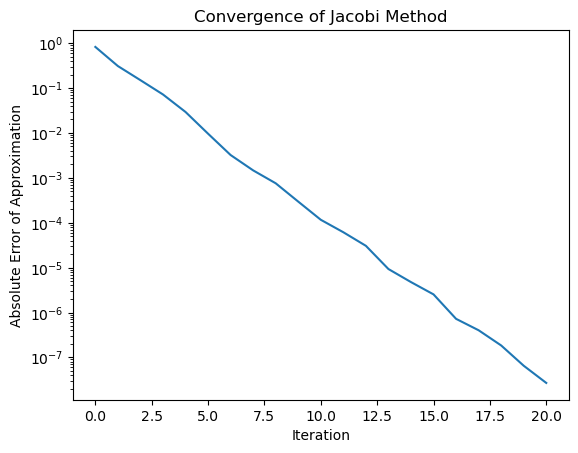

In [6]:
np.random.seed(2)
A = diag_dom(100)
b = np.random.random(100)
x = jacobi_method(A, b, plot=True)
assert np.allclose(A @ x, b)

## The Gauss-Seidel Method

The Gauss-Seidel method is a slight modification of the Jacobi method in which new information is used immediately. For the same $3 \times 3$ system, compute $x_1^{(1)} = \frac{1}{2}(3 + x_3^{(0)}) = \frac{3}{2}$ as before, but then use the updated $x_1^{(1)}$ to compute $x_2^{(1)}$, and the updated $x_1^{(1)}$ and $x_2^{(1)}$ to compute $x_3^{(1)}$:

$$x_2^{(1)} = \tfrac{1}{3}\left(3 + x_1^{(1)} - 2x_3^{(0)}\right) = \tfrac{1}{3}\left(3 + \tfrac{3}{2} - 0\right) = \tfrac{3}{2}, \qquad x_3^{(1)} = \tfrac{1}{3}\left(-1 - x_2^{(1)}\right) = \tfrac{1}{3}\left(-1 - \tfrac{3}{2}\right) = -\tfrac{5}{6}.$$

This process of using calculated information immediately is called *forward substitution*, and causes the algorithm to (generally) converge much faster.

| | $x_1^{(k)}$ | $x_2^{(k)}$ | $x_3^{(k)}$ |
|---|---|---|---|
| $\mathbf{x}^{(0)}$ | 0 | 0 | 0 |
| $\mathbf{x}^{(1)}$ | 1.5 | 1.5 | -0.833333 |
| $\mathbf{x}^{(2)}$ | 1.08333333 | 1.91666667 | -0.97222222 |
| $\mathbf{x}^{(3)}$ | 1.01388889 | 1.98611111 | -0.99537037 |
| $\mathbf{x}^{(4)}$ | 1.00231481 | 1.99768519 | -0.9992284 |
| ... | ... | ... | ... |
| $\mathbf{x}^{(11)}$ | 1.00000001 | 1.99999999 | -1 |
| $\mathbf{x}^{(12)}$ | 1 | 2 | -1 |

Gauss-Seidel converges in less than half as many iterations as Jacobi does for this system.

### Implementation

Because Gauss-Seidel updates only one element of the solution vector at a time, the iteration cannot be summarized by a single matrix equation. It is most generally described by

$$x_i^{(k+1)} = \frac{1}{a_{ii}}\left(b_i - \sum_{j<i} a_{ij}x_j^{(k)} - \sum_{j>i} a_{ij}x_j^{(k)}\right). \tag{16.3}$$

Let $A_i$ be the $i$th row of $A$. The two sums closely resemble the regular vector product of $A_i$ and $\mathbf{x}^{(k)}$ without the $i$th term $a_{ii}x_i^{(k)}$, which suggests the simplification

$$x_i^{(k+1)} = \frac{1}{a_{ii}}\left(b_i - A_i^T\mathbf{x}^{(k)} + a_{ii}x_i^{(k)}\right) = x_i^{(k)} + \frac{1}{a_{ii}}\left(b_i - A_i^T\mathbf{x}^{(k)}\right). \tag{16.4}$$

One sweep through all the entries of $\mathbf{x}$ completes one iteration.

## Problem 3: The Gauss-Seidel method

> **Problem 3.** Write a function that accepts a matrix $A$, a vector $\mathbf{b}$, a convergence tolerance `tol`, a maximum number of iterations `maxiters`, and a keyword argument `plot` that defaults to `False`. Implement the Gauss-Seidel method using (16.4), returning the approximate solution to the equation $A\mathbf{x} = \mathbf{b}$.
>
> Use the same stopping criterion as in Problem 1. Also keep track of the absolute errors of the iteration, as in Problem 2. If `plot` is `True`, plot the error against iteration count. Use `diag_dom()` to generate test cases.

In [7]:
def gauss_seidel(A, b, tol=1e-8, maxiters=100, plot=False):
    """Calculate the solution to the system Ax = b via the Gauss-Seidel Method.

    Parameters:
        A ((n, n) ndarray): A square matrix.
        b ((n, ) ndarray): A vector of length n.
        tol (float): The convergence tolerance.
        maxiters (int): The maximum number of iterations to perform.
        plot (bool): If true, plot the convergence rate of the algorithm.

    Returns:
        x ((n,) ndarray): The solution to system Ax = b.
    """
    n = len(b)
    # Initial guess
    x0 = np.zeros(n)
    # Keep track of the errors in case plot=True
    error = []
    for i in range(maxiters):
        # 16.4
        x1 = np.copy(x0)
        for j in range(len(x0)):
            x1[j] += 1/A[j,j]*(b[j] - np.dot(A[j],x1))
        # Fixed: track the absolute error ||Ax - b||_inf (as in Problem 2);
        # this was ||x1 - x0||_inf.
        error.append(la.norm(A@x1-b, ord=np.inf))
        # Stopping criteria
        if la.norm(x1-x0, ord=np.inf) < tol:
            # Plot the error as a function of iterations
            if plot == True:
                plt.semilogy(np.arange(0,i+1), error)
                plt.title("Convergence of Gauss Seidel Method")
                plt.xlabel("Iteration")
                plt.ylabel("Absolute Error of Approximation")
                plt.show()
            return x1
        x0 = x1
    # Plot the error as a function of iterations
    if plot == True:
        plt.semilogy(np.arange(0,maxiters), error)
        plt.title("Convergence of Gauss Seidel Method")
        plt.xlabel("Iteration")
        plt.ylabel("Absolute Error of Approximation")
        plt.show()
    return x1

The $3 \times 3$ example reproduces the Gauss-Seidel table, and the same diagonally dominant test systems as for Jacobi:

In [8]:
for k in [1, 2, 3, 4, 11]:
    print(f"x({k}) =", gauss_seidel(A3, b3, maxiters=k))
assert np.allclose(gauss_seidel(A3, b3), [1, 2, -1])

np.random.seed(15)
for n in [5, 20, 100, 500]:
    A = diag_dom(n)
    b = np.random.random(n)
    x = gauss_seidel(A, b)
    assert np.allclose(A @ x, b)
    assert np.allclose(x, la.solve(A, b))
print("All checks passed.")

x(1) = [ 1.5         1.5        -0.83333333]
x(2) = [ 1.08333333  1.91666667 -0.97222222]
x(3) = [ 1.01388889  1.98611111 -0.99537037]
x(4) = [ 1.00231481  1.99768519 -0.9992284 ]
x(11) = [ 1.00000001  1.99999999 -1.        ]
All checks passed.


The convergence plot for the same system as the Jacobi plot in Problem 2, which converges in far fewer iterations:

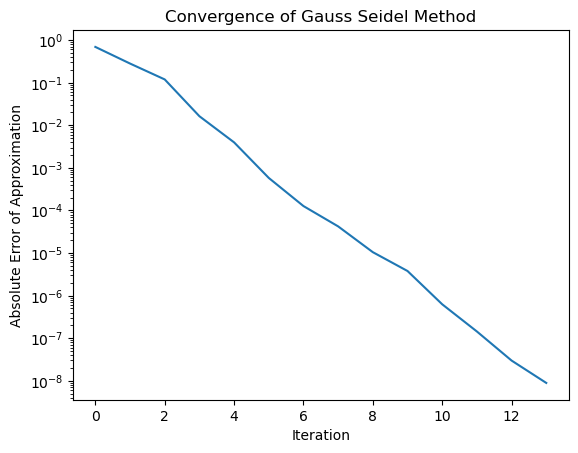

In [9]:
np.random.seed(2)
A = diag_dom(100)
b = np.random.random(100)
x = gauss_seidel(A, b, plot=True)
assert np.allclose(A @ x, b)

> **Achtung!** Since the Gauss-Seidel algorithm operates on the approximation vector in place (modifying it one entry at a time), the previous approximation $\mathbf{x}^{(k-1)}$ must be stored at the beginning of the $k$th iteration in order to calculate $\|\mathbf{x}^{(k-1)} - \mathbf{x}^{(k)}\|_\infty$. Additionally, since NumPy arrays are mutable, the past iteration must be stored as a copy.

In [10]:
x0 = np.random.random(5)            # Generate a random vector.
x1 = x0                             # Attempt to make a copy.
x1[3] = 1000                        # Modify the "copy" in place.
print(np.allclose(x0, x1))          # But x0 was also changed!

# Instead, make a copy of x0 when creating x1.
x0 = np.copy(x1)                    # Make a copy.
x1[3] = -1000
print(np.allclose(x0, x1))

True
False


### Convergence

Whether the Gauss-Seidel method converges depends on the nature of $A$. If all of the eigenvalues of $A$ are positive, $A$ is called *positive definite*. If $A$ is positive definite or strictly diagonally dominant, then the Gauss-Seidel method converges regardless of the initial guess $\mathbf{x}^{(0)}$.

## Solving Sparse Systems Iteratively

Iterative solvers are best suited for solving very large sparse systems. Using the Gauss-Seidel method on sparse matrices requires translating code from NumPy to `scipy.sparse`; the algorithm is the same, but some functions are named differently between the two packages (see the Linear Systems lab for a review of `scipy.sparse`).

## Problem 4: Sparse Gauss-Seidel

> **Problem 4.** Write a new function that accepts a sparse matrix $A$, a vector $\mathbf{b}$, a convergence tolerance `tol`, and a maximum number of iterations `maxiters` (plotting the convergence is not required for this problem). Implement the Gauss-Seidel method using (16.4), returning the approximate solution to the equation $A\mathbf{x} = \mathbf{b}$. Use the usual stopping criterion.
>
> The Gauss-Seidel method requires extracting the rows $A_i$ from the matrix $A$ and computing $A_i^T\mathbf{x}$. There are many ways to do this that cause some fairly serious runtime issues, so we provide the code for this specific portion of the algorithm.
>
> ```python
> # Get the indices of where the i-th row of A starts and ends if the
> # nonzero entries of A were flattened.
> rowstart = A.indptr[i]
> rowend = A.indptr[i+1]
>
> # Multiply only the nonzero elements of the i-th row of A with the
> # corresponding elements of x.
> Aix = A.data[rowstart:rowend] @ x[A.indices[rowstart:rowend]]
> ```
>
> To test your function, cast the result of `diag_dom()` as a sparse matrix.
>
> ```python
> >>> from scipy import sparse
> >>> A = sparse.csr_matrix(diag_dom(50000))
> >>> b = np.random.random(50000)
> ```

In [11]:
def gauss_seidel_sparse(A, b, tol=1e-8, maxiters=100):
    """Calculate the solution to the sparse system Ax = b via the Gauss-Seidel
    Method.

    Parameters:
        A ((n, n) csr_matrix): A (n, n) sparse CSR matrix.
        b ((n, ) ndarray): A vector of length n.
        tol (float): The convergence tolerance.
        maxiters (int): the maximum number of iterations to perform.

    Returns:
        x ((n,) ndarray): The solution to system Ax = b.
    """
    n = len(b)
    # Initial guess
    x0 = np.zeros(n)
    for i in range(maxiters):
        # 16.4 modified for csr matrix
        x1 = np.copy(x0)
        for j in range(len(x0)):
            rowstart = A.indptr[j]
            rowend = A.indptr[j+1]
            Ajx = A.data[rowstart:rowend] @ x1[A.indices[rowstart:rowend]]
            x1[j] += 1/A[j,j]*(b[j] - Ajx)
        # Stopping criteria
        if la.norm(x1-x0, ord=np.inf) < tol:
            return x1
        x0 = x1
    return x1

> **Note.** The spec's test size of $n = 50000$ is run here at $n = 5000$. `diag_dom()` builds a dense NumPy array before it is cast to sparse, and a dense $50000 \times 50000$ array of floats takes 20 GB of memory.

The solution is compared with SciPy's sparse direct solver `spsolve()`. With the default `tol=1e-8`, $\mathbf{x}$ agrees with it to about $10^{-9}$, but the diagonal entries of this $A$ are in the hundreds, so $A\mathbf{x}$ only matches $\mathbf{b}$ to about $10^{-7}$, outside `np.allclose()`'s default absolute tolerance of $10^{-8}$ for the entries of $\mathbf{b}$ near 0. A tighter `tol` gives $A\mathbf{x} \approx \mathbf{b}$ to `np.allclose()`'s standard.

In [12]:
np.random.seed(4)
n = 5000
A = sparse.csr_matrix(diag_dom(n))
b = np.random.random(n)
print(f"{A.nnz} nonzero entries ({A.nnz / n**2:.2%} of the matrix)")

x = gauss_seidel_sparse(A, b)
x_direct = spla.spsolve(A.tocsc(), b)
print("max |x - spsolve(A, b)| =", la.norm(x - x_direct, ord=np.inf))
print("max |Ax - b|            =", la.norm(A @ x - b, ord=np.inf))
assert np.allclose(x, x_direct)

x = gauss_seidel_sparse(A, b, tol=1e-12, maxiters=1000)
assert np.allclose(A @ x, b)
print("All checks passed.")

308162 nonzero entries (1.23% of the matrix)


max |x - spsolve(A, b)| = 4.979664536622352e-10
max |Ax - b|            = 6.584064338177598e-08


All checks passed.


## Successive Over-Relaxation

Many systems meet the requirements for convergence with the Gauss-Seidel method but still converge relatively slowly. A slightly altered version, *Successive Over-Relaxation* (SOR), can converge faster. It introduces a relaxation factor $\omega \ge 1$ and modifies (16.3) to

$$x_i^{(k+1)} = (1 - \omega)x_i^{(k)} + \frac{\omega}{a_{ii}}\left(b_i - \sum_{j<i} a_{ij}x_j^{(k)} - \sum_{j>i} a_{ij}x_j^{(k)}\right),$$

which simplifies to

$$x_i^{(k+1)} = x_i^{(k)} + \frac{\omega}{a_{ii}}\left(b_i - A_i^T\mathbf{x}^{(k)}\right). \tag{16.5}$$

When $\omega = 1$, SOR reduces to Gauss-Seidel. The relaxation factor $\omega$ weights the new iteration between the current best approximation and the next approximation in a way that can sometimes dramatically improve convergence.

## Problem 5: Successive Over-Relaxation

> **Problem 5.** Write a function that accepts a sparse matrix $A$, a vector $\mathbf{b}$, a relaxation factor $\omega$, a convergence tolerance `tol`, and a maximum number of iterations `maxiters`. Implement SOR using (16.5), compute the approximate solution to the equation $A\mathbf{x} = \mathbf{b}$. Use the usual stopping criterion. Return the approximate solution $\mathbf{x}$ as well as the number of iterations computed.
>
> (Hint: this requires changing only one line of code from the sparse Gauss-Seidel function.)

In [13]:
def sor(A, b, omega, tol=1e-8, maxiters=100):
    """Calculate the solution to the system Ax = b via Successive Over-
    Relaxation.

    Parameters:
        A ((n, n) csr_matrix): A (n, n) sparse matrix.
        b ((n, ) Numpy Array): A vector of length n.
        omega (float >= 1): The relaxation factor.
        tol (float): The convergence tolerance.
        maxiters (int): The maximum number of iterations to perform.

    Returns:
        ((n,) ndarray): The solution to system Ax = b.
        (int): The number of iterations computed.
    """
    n = len(b)
    # Initial guess
    x0 = np.zeros(n)
    for i in range(maxiters):
        # 16.5
        x1 = np.copy(x0)
        for j in range(len(x0)):
            rowstart = A.indptr[j]
            rowend = A.indptr[j+1]
            Ajx = A.data[rowstart:rowend] @ x1[A.indices[rowstart:rowend]]
            x1[j] += omega/A[j,j]*(b[j] - Ajx)
        # Stopping criteria
        if la.norm(x1-x0, ord=np.inf) < tol:
            return x1, i+1      # Fixed: was i, one less than the iterations computed (i is 0-based).
        x0 = x1
    return x1, maxiters

With $\omega = 1$, SOR must give exactly the sparse Gauss-Seidel result. For other values of $\omega$ it converges to the same solution; on this strongly diagonally dominant system Gauss-Seidel is already fast, and larger $\omega$ only adds iterations. The hot plate system below is where SOR pays off.

In [14]:
x_sor, k = sor(A, b, 1)
assert np.allclose(x_sor, gauss_seidel_sparse(A, b))
print(f"omega = 1.00: {k:3} iterations")
for omega in [1.05, 1.1, 1.2, 1.5]:
    x_sor, k = sor(A, b, omega)
    assert np.allclose(x_sor, x_direct)
    print(f"omega = {omega:.2f}: {k:3} iterations")

omega = 1.00:   8 iterations


omega = 1.05:   8 iterations


omega = 1.10:  10 iterations


omega = 1.20:  13 iterations


omega = 1.50:  36 iterations


## A Finite Difference Method

Laplace's equation is an important partial differential equation that arises often in both pure and applied mathematics. In two dimensions it is

$$\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} = 0. \tag{16.6}$$

It can model heat flow. Consider a square metal plate whose top and bottom borders are fixed at 0° Celsius and whose left and right sides are fixed at 100° Celsius. The solution to Laplace's equation describes the plate in a *steady state*, when the heat at a given part of the plate no longer changes with time.

Equation (16.6) can be solved analytically, but also numerically with a *finite difference method*. Impose a discrete, square grid with uniform spacing on the plate, with points $(x_i, y_j)$ and heat values $u(x_i, y_j) = U_{i,j}$. Using the centered difference quotient for second derivatives,

$$0 = \frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} \approx \frac{U_{i+1,j} - 2U_{i,j} + U_{i-1,j}}{h^2} + \frac{U_{i,j+1} - 2U_{i,j} + U_{i,j-1}}{h^2} = \frac{1}{h^2}\left(-4U_{i,j} + U_{i+1,j} + U_{i-1,j} + U_{i,j+1} + U_{i,j-1}\right), \tag{16.7}$$

where $h = x_{i+1} - x_i = y_{j+1} - y_j$ is the grid spacing. If the grid has exactly $(n + 2) \times (n + 2)$ entries, the interior (where $u(x, y)$ is unknown) is $n \times n$ and can be flattened into an $n^2 \times 1$ vector, row by row:

$$\mathbf{u} = [U_{1,1}, U_{1,2}, \cdots, U_{1,n}, U_{2,1}, U_{2,2}, \cdots, U_{2,n}, \ldots, U_{n,n}]^T.$$

From (16.7), each interior point satisfies

$$-4U_{i,j} + U_{i+1,j} + U_{i-1,j} + U_{i,j+1} + U_{i,j-1} = 0. \tag{16.8}$$

If a neighbor of $U_{i,j}$ is a boundary point, its value is fixed by the boundary conditions and moves to the right side. For example, the neighbor $U_{3,0}$ of $U_{3,1}$ is fixed at $U_{3,0} = 100$, so (16.8) becomes $-4U_{3,1} + U_{2,1} + U_{3,2} + U_{4,1} = -100$. These constants form the $n^2 \times 1$ vector $\mathbf{b}$, whose nonzero entries correspond to interior points that touch the left or right boundaries.

The spec's Figure 16.1 shows a $6 \times 6$ grid ($n = 4$), with hot boundary points on the left and right, cold ones on the top and bottom, and the four neighbors used to approximate the heat at an interior point. Writing (16.8) for its 16 interior points gives a $16 \times 16$ system $A\mathbf{u} = \mathbf{b}$ with

$$\mathbf{b} = [-100, 0, 0, -100, \; -100, 0, 0, -100, \; -100, 0, 0, -100, \; -100, 0, 0, -100]^T.$$

For any positive integer $n$, the matrix has the block form

$$A = \begin{bmatrix} B & I & & & \\ I & B & I & & \\ & I & \ddots & \ddots & \\ & & \ddots & \ddots & I \\ & & & I & B \end{bmatrix}, \quad \text{where} \quad B = \begin{bmatrix} -4 & 1 & & & \\ 1 & -4 & 1 & & \\ & 1 & \ddots & \ddots & \\ & & \ddots & \ddots & 1 \\ & & & 1 & -4 \end{bmatrix} \text{ is } n \times n.$$

## Problem 6: The hot plate

> **Problem 6.** Write a function that accepts an integer $n$, a relaxation factor $\omega$, a convergence tolerance `tol` that defaults to $10^{-8}$, a maximum number of iterations `maxiters` that defaults to 100, and a bool `plot` that defaults to `False`. Generate and solve the corresponding system $A\mathbf{u} = \mathbf{b}$ using Problem 5. Also return the number of iterations computed.
>
> (Hint: see Problem 5 of the Linear Systems lab for the construction of $A$. Also, `np.tile()` may be useful for constructing $\mathbf{b}$.)
>
> If `plot=True`, visualize the solution $\mathbf{u}$ with a heatmap using `plt.pcolormesh()` (the colormap `"coolwarm"` is a good choice in this case). This shows the distribution of heat over the hot plate after it has reached its steady state. Note that the $\mathbf{u}$ must be reshaped as an $n \times n$ array to properly visualize the result.

In [15]:
def hot_plate(n, omega, tol=1e-8, maxiters=100, plot=False):
    """Generate the system Au = b and then solve it using sor().
    If plot is True, visualize the solution with a heatmap.

    Parameters:
        n (int): Determines the size of A and b.
            A is (n^2, n^2) and b is one-dimensional with n^2 entries.
        omega (float >= 1): The relaxation factor.
        tol (float): The iteration tolerance.
        maxiters (int): The maximum number of iterations.
        plot (bool): Whether or not to visualize the solution.

    Returns:
        ((n^2,) ndarray): The 1-D solution vector u of the system Au = b.
        (int): The number of computed iterations in SOR.
    """
    def create_A(n):
        """Let I be the n × n identity matrix, and define
                        [B I        ]        [-4  1            ]
                        [I B I      ]        [ 1 -4  1         ]
                    A = [  I . .    ]    B = [    1  .  .      ],
                        [      . . I]        [          .  .  1]
                        [        I B]        [             1 -4]
        where A is (n**2,n**2) and each block B is (n,n).
        Construct and returns A as a sparse matrix.

        Parameters:
            n (int): Dimensions of the sparse matrix B.

        Returns:
            A ((n**2,n**2) SciPy sparse matrix)
        """
        Iden = sparse.diags([1], [0], shape=(n,n))
        B = sparse.diags([1,-4,1], [-1,0,1], shape=(n,n))
        A = sparse.lil_matrix((n**2, n**2))
        for i in range(n):
            A[i*n:(i+1)*n,i*n:(i+1)*n] = B
            if i > 0:
                A[(i-1)*n:i*n,i*n:(i+1)*n] = Iden
                A[i*n:(i+1)*n,(i-1)*n:i*n] = Iden
        return A
    A = sparse.csr_matrix(create_A(n))
    c = np.zeros(n)
    c[0] = -100
    c[-1] = -100
    b = np.tile(c, n)
    u, i = sor(A, b, omega, tol=tol, maxiters=maxiters)
    if plot == True:
        plt.pcolormesh(u.reshape((n,n)), cmap="coolwarm")
        plt.show()

    return u, i

A check against a direct solve: the same system built independently with Kronecker products, $A = I \otimes B + T \otimes I$ where $T$ has ones on its first sub- and superdiagonals, and solved with `spsolve()`. For $n = 4$ the solution is symmetric left to right and top to bottom, like the plate.

In [16]:
def hot_plate_direct(n):
    B = sparse.diags([1, -4, 1], [-1, 0, 1], shape=(n, n))
    T = sparse.diags([1, 1], [-1, 1], shape=(n, n))
    A = sparse.kron(sparse.identity(n), B) + sparse.kron(T, sparse.identity(n))
    b = np.tile(np.r_[-100, np.zeros(n-2), -100], n)
    return spla.spsolve(A.tocsc(), b)

u, k = hot_plate(4, 1, tol=1e-12, maxiters=1000)
print(f"{k} iterations")
print(np.round(u.reshape(4, 4), 4))
assert np.allclose(u, hot_plate_direct(4))
for n, omega in [(10, 1.5), (20, 1.8)]:
    u, k = hot_plate(n, omega, tol=1e-12, maxiters=5000)
    assert np.allclose(u, hot_plate_direct(n))
print("All checks passed.")

75 iterations
[[50.     33.3333 33.3333 50.    ]
 [66.6667 50.     50.     66.6667]
 [66.6667 50.     50.     66.6667]
 [50.     33.3333 33.3333 50.    ]]


All checks passed.


The steady state of a plate with $n = 40$, solved with $\omega = 1.9$ (rows of the grid run bottom to top, so the hot left and right sides are red and the cold top and bottom are blue):

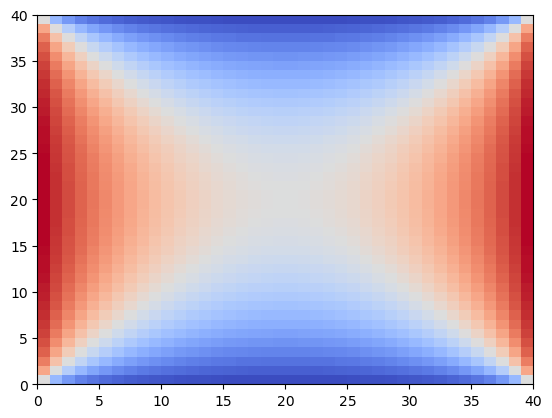

247 iterations


In [17]:
u, k = hot_plate(40, 1.9, maxiters=1000, plot=True)
print(f"{k} iterations")

## Problem 7: Choosing the relaxation factor

> **Problem 7.** To demonstrate how convergence is affected by the value of the relaxation factor $\omega$ in SOR, run your function from Problem 6 with $\omega = 1, 1.05, 1.1, \ldots, 1.9, 1.95$ and $n = 20$. Plot the number of computed iterations as a function of $\omega$. Return the value of $\omega$ that results in the least number of iterations.
>
> Note that the matrix $A$ from Problem 6 is not strictly diagonally dominant. However, $A$ is positive definite, so the algorithm will converge. Unfortunately, convergence for these kinds of systems usually requires more iterations than for strictly diagonally dominant systems. Therefore, set `tol=1e-2` and `maxiters=1000`.

The matrix in Problem 6 has $-4$ on the diagonal, so strictly it is $-A$ that is positive definite; the system $-A\mathbf{u} = -\mathbf{b}$ has the same solution and the same SOR iterates.

In [18]:
def prob7():
    """Run hot_plate() with omega = 1, 1.05, 1.1, ..., 1.9, 1.95, tol=1e-2,
    and maxiters = 1000 with A and b generated with n=20. Plot the iterations
    computed as a function of omega.
    """
    omegas = np.arange(100, 200, 5)/100
    n = 20
    iterations = []
    for omega in omegas:
        u, i = hot_plate(n, omega, tol=1e-2, maxiters=1000)
        iterations.append(i)
    plt.plot(omegas, iterations)
    plt.ylabel("iterations")
    plt.xlabel("omega")
    plt.show()
    return omegas[np.argmin(iterations)]

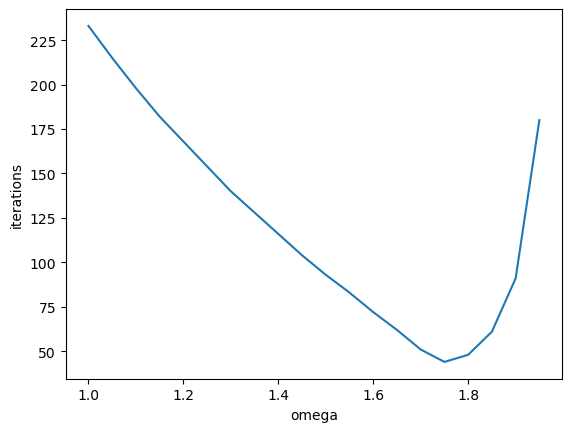

Best omega: 1.75


Iterations: omega = 1 -> 233    omega = 1.75 -> 44


In [19]:
best = prob7()
print("Best omega:", best)
print("Iterations: omega = 1 ->", hot_plate(20, 1, tol=1e-2, maxiters=1000)[1],
      "   omega =", best, "->", hot_plate(20, best, tol=1e-2, maxiters=1000)[1])

Recall that $\omega = 1$ corresponds to the Gauss-Seidel method. Choosing a more optimal relaxation factor saves a large number of iterations. This could translate to saving days or weeks of computation time while solving extremely large linear systems on a supercomputer.